# Credit Card Fraud Detection — Exploratory Data Analysis (EDA)

## Project Overview
Credit card fraud detection is critical for safeguarding electronic payment systems. Fraudulent activity often presents anomalies in purchasing patterns, unusual transaction distances, and lack of standard point-of-sale verification (such as PIN entry or EMV chip readers).

## Dataset Overview (`card_transdata.csv`)
The dataset includes the following transaction attributes:
- `distance_from_home`: Distance from the cardholder's home address to the transaction venue.
- `distance_from_last_transaction`: Distance from the location of the previous transaction.
- `ratio_to_median_purchase_price`: Ratio of the transaction purchase price to the cardholder's historical median price.
- `repeat_retailer`: Whether the transaction was with a previously visited merchant (1 = Yes, 0 = No).
- `used_chip`: Whether an EMV chip was used (1 = Yes, 0 = No).
- `used_pin_number`: Whether a PIN was verified (1 = Yes, 0 = No).
- `online_order`: Whether the purchase was an online order (1 = Yes, 0 = No).
- `fraud`: Binary target variable indicating fraud status (1 = Fraudulent, 0 = Legitimate / Not Fraud).

## EDA Requirements Covered in this Notebook
1. **Univariate Analysis**:
   - Class distribution (`fraud`)
   - Used PIN number distribution (`used_pin_number`)
   - Repeat retailer distribution (`repeat_retailer`)
   - Online order distribution (`online_order`)
   - Full range histogram for `ratio_to_median_purchase_price`
   - Full range histogram for `distance_from_home`
2. **Bivariate Analysis (Comparing Fraudulent vs. Not Fraudulent)**:
   - Standalone graph for the **number** of transactions where PIN was vs. wasn't used
   - Standalone graph for the **percent** of transactions where PIN was vs. wasn't used
   - Standalone graph for the **number** of transactions where Chip was vs. wasn't used
   - Standalone graph for the **percent** of transactions where Chip was vs. wasn't used
   - Standalone graph for the **number** of transactions done through online orders
   - Standalone graph for the **percent** of transactions done through online orders
   - Standalone scatter plot comparing `distance_from_last_transaction` vs. `ratio_to_median_purchase_price`
3. **Key Findings & Summary Insights**:
   - Comprehensive synthesis and risk indicators for modeling.


## 1. Setup & Environment Configuration
Importing core data manipulation and visualization libraries: **pandas**, **seaborn**, and **matplotlib**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress minor future warnings for clean output
warnings.filterwarnings('ignore')

# Matplotlib & Seaborn styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Shared palette for fraud comparison
FRAUD_PALETTE = {'Not Fraud': '#2b7bba', 'Fraud': '#d9534f'}

print("✓ Libraries imported successfully:")
print(f"  - pandas: {pd.__version__}")
print(f"  - seaborn: {sns.__version__}")
import matplotlib
print(f"  - matplotlib: {matplotlib.__version__}")


✓ Libraries imported successfully:
  - pandas: 3.0.6
  - seaborn: 0.13.2
  - matplotlib: 3.11.2


## 2. Data Loading & Initial Inspection
Loading `card_transdata.csv` and inspecting its dimensions, column types, statistical summaries, and missing values.

In [2]:
# Load dataset
df = pd.read_csv('card_transdata.csv')

print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns\n")
df.head(10)


Dataset Shape: 999 rows and 8 columns



,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0
7,4.848247,0.320735,1.273050,1.0,0.0,1.0,0.0,0
8,0.876632,2.503609,1.516999,0.0,0.0,0.0,0.0,0
9,8.839047,2.970512,2.361683,1.0,0.0,0.0,1.0,0


In [3]:
# Data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [4]:
# Five-number summary and basic statistics
df.describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
distance_from_home,999.0,26.877,63.900,0.104,3.991,10.340,25.394,965.911
distance_from_last_transaction,996.0,5.437,35.668,0.001,0.306,0.959,3.137,990.070
ratio_to_median_purchase_price,997.0,1.655,2.351,0.017,0.468,0.956,1.922,36.074
repeat_retailer,992.0,0.892,0.310,0.000,1.000,1.000,1.000,1.000
used_chip,995.0,0.314,0.464,0.000,0.000,0.000,1.000,1.000
used_pin_number,997.0,0.117,0.322,0.000,0.000,0.000,0.000,1.000
online_order,995.0,0.673,0.469,0.000,0.000,1.000,1.000,1.000
fraud,999.0,0.079,0.270,0.000,0.000,0.000,0.000,1.000


In [5]:
# Check for missing values
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_pct.round(2)})
missing_df[missing_df['Missing Count'] > 0]


,Missing Count,Percentage (%)
distance_from_last_transaction,3,0.3
ratio_to_median_purchase_price,2,0.2
repeat_retailer,7,0.7
used_chip,4,0.4
used_pin_number,2,0.2
online_order,4,0.4


### 2.1 Data Cleaning & Feature Preparation
We drop the few incomplete records (< 1% missing values per column) and create human-readable categorical labels for clean, standalone visualizations.

In [6]:
# Drop rows with missing values
df_clean = df.dropna().copy()

# Add readable categorical label columns
df_clean['fraud_label'] = df_clean['fraud'].map({0: 'Not Fraud', 1: 'Fraud'})
df_clean['pin_label'] = df_clean['used_pin_number'].map({0: 'No PIN', 1: 'PIN Used'})
df_clean['chip_label'] = df_clean['used_chip'].map({0: 'No Chip', 1: 'Chip Used'})
df_clean['repeat_label'] = df_clean['repeat_retailer'].map({0: 'New Retailer', 1: 'Repeat Retailer'})
df_clean['online_label'] = df_clean['online_order'].map({0: 'In-Person', 1: 'Online Order'})

print(f"Original record count: {len(df):,}")
print(f"Cleaned record count:  {len(df_clean):,} ({len(df) - len(df_clean)} incomplete rows dropped)")


Original record count: 999
Cleaned record count:  977 (22 incomplete rows dropped)


---
# 3. Univariate Analysis

Univariate analysis explores each feature individually to evaluate its frequency distribution, central tendency, spread, and anomalies.

We analyze:
1. **Class Distribution (`fraud`)**
2. **Used PIN Number Distribution (`used_pin_number`)**
3. **Repeat Retailer Distribution (`repeat_retailer`)**
4. **Online Order Distribution (`online_order`)**
5. **Full Range Histogram of `ratio_to_median_purchase_price`**
6. **Full Range Histogram of `distance_from_home`**


### 3.1 Class Distribution (`fraud`)
Examining the class balance between legitimate (`Not Fraud`) and fraudulent (`Fraud`) transactions.

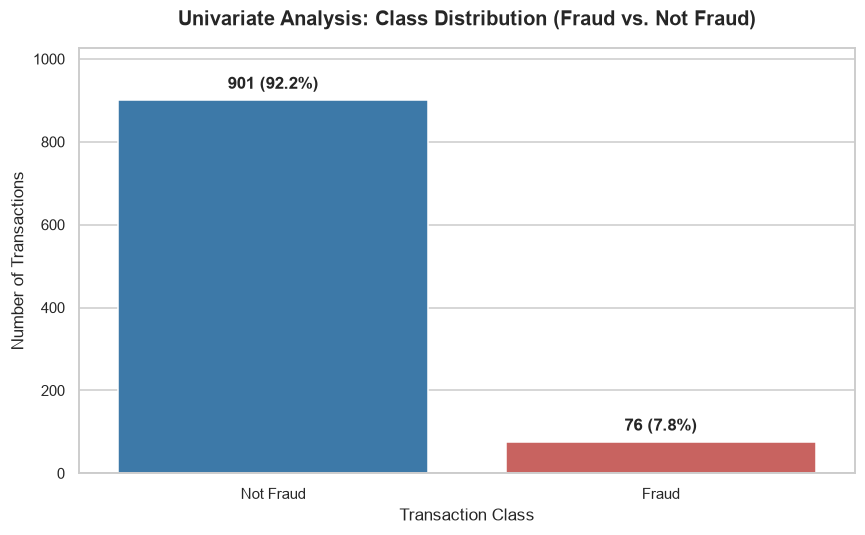

Class counts:
fraud_label
Not Fraud    901
Fraud         76
Name: count, dtype: int64

Class proportions (%):
fraud_label
Not Fraud    92.22
Fraud         7.78
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(8, 5))
order_fraud = ['Not Fraud', 'Fraud']
palette_fraud = {'Not Fraud': '#2b7bba', 'Fraud': '#d9534f'}

ax = sns.countplot(
    data=df_clean,
    x='fraud_label',
    order=order_fraud,
    palette=palette_fraud
)

plt.title('Univariate Analysis: Class Distribution (Fraud vs. Not Fraud)', fontweight='bold', pad=15)
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')
plt.ylim(0, len(df_clean) * 1.05)

total_fraud = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total_fraud) * 100
    ax.annotate(f"{int(height):,} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

print("Class counts:")
print(df_clean['fraud_label'].value_counts())
print("\nClass proportions (%):")
print((df_clean['fraud_label'].value_counts(normalize=True) * 100).round(2))


### 3.2 Used PIN Number Distribution (`used_pin_number`)
Examining the overall proportion of transactions that verified a PIN.

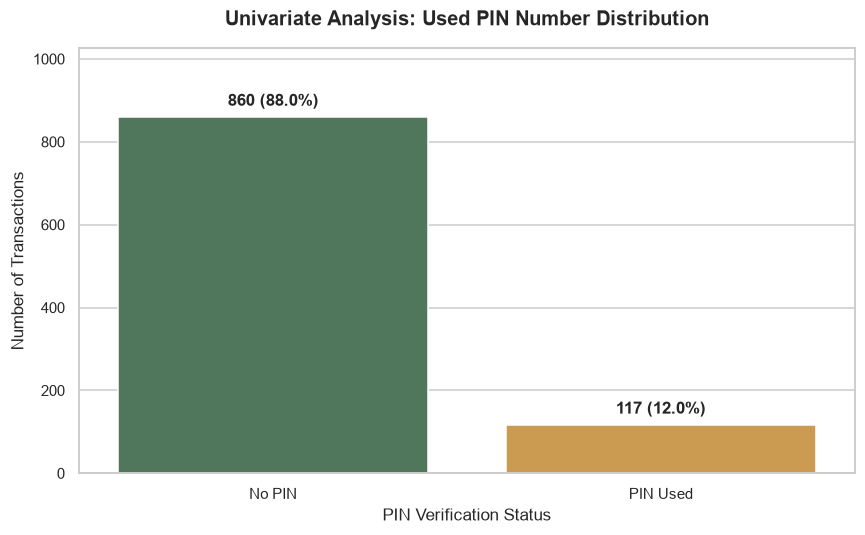

PIN Usage counts:
pin_label
No PIN      860
PIN Used    117
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 5))
order_pin = ['No PIN', 'PIN Used']
palette_pin = {'No PIN': '#4a7c59', 'PIN Used': '#e09f3e'}

ax = sns.countplot(
    data=df_clean,
    x='pin_label',
    order=order_pin,
    palette=palette_pin
)

plt.title('Univariate Analysis: Used PIN Number Distribution', fontweight='bold', pad=15)
plt.xlabel('PIN Verification Status')
plt.ylabel('Number of Transactions')
plt.ylim(0, len(df_clean) * 1.05)

total_pin = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total_pin) * 100
    ax.annotate(f"{int(height):,} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

print("PIN Usage counts:")
print(df_clean['pin_label'].value_counts())


### 3.3 Repeat Retailer Distribution (`repeat_retailer`)
Examining transactions conducted at a previously visited retailer versus a first-time/new retailer.

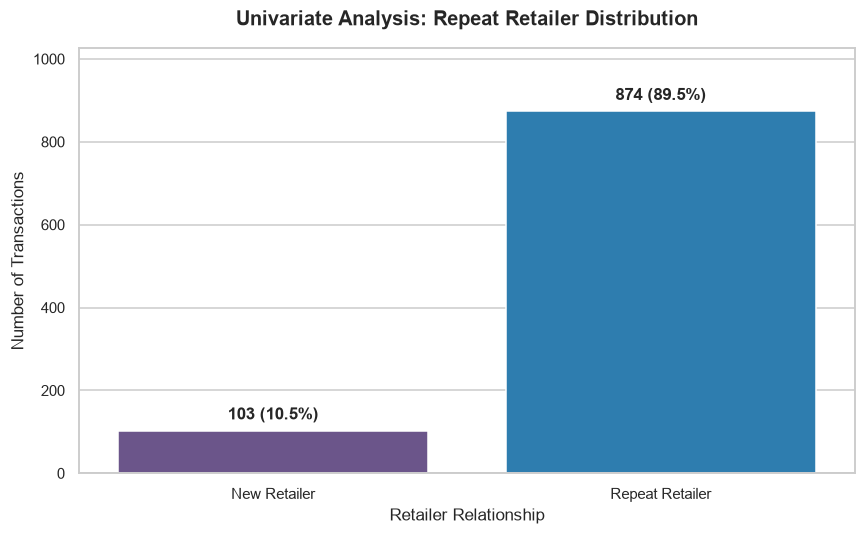

Repeat Retailer counts:
repeat_label
Repeat Retailer    874
New Retailer       103
Name: count, dtype: int64


In [9]:
plt.figure(figsize=(8, 5))
order_rep = ['New Retailer', 'Repeat Retailer']
palette_rep = {'New Retailer': '#6a4c93', 'Repeat Retailer': '#1982c4'}

ax = sns.countplot(
    data=df_clean,
    x='repeat_label',
    order=order_rep,
    palette=palette_rep
)

plt.title('Univariate Analysis: Repeat Retailer Distribution', fontweight='bold', pad=15)
plt.xlabel('Retailer Relationship')
plt.ylabel('Number of Transactions')
plt.ylim(0, len(df_clean) * 1.05)

total_rep = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total_rep) * 100
    ax.annotate(f"{int(height):,} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

print("Repeat Retailer counts:")
print(df_clean['repeat_label'].value_counts())


### 3.4 Online Order Distribution (`online_order`)
Examining the breakdown between online e-commerce transactions and in-person card transactions.

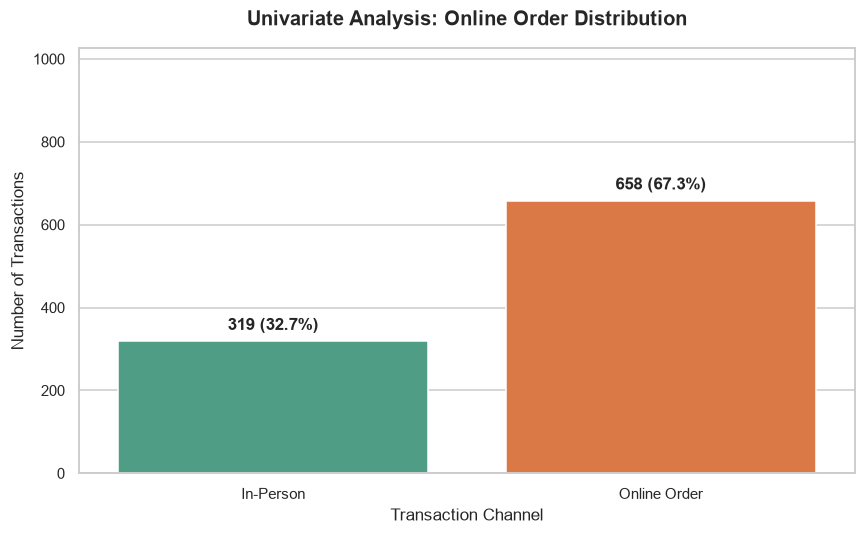

Online Order counts:
online_label
Online Order    658
In-Person       319
Name: count, dtype: int64


In [10]:
plt.figure(figsize=(8, 5))
order_online = ['In-Person', 'Online Order']
palette_online = {'In-Person': '#43aa8b', 'Online Order': '#f3722c'}

ax = sns.countplot(
    data=df_clean,
    x='online_label',
    order=order_online,
    palette=palette_online
)

plt.title('Univariate Analysis: Online Order Distribution', fontweight='bold', pad=15)
plt.xlabel('Transaction Channel')
plt.ylabel('Number of Transactions')
plt.ylim(0, len(df_clean) * 1.05)

total_online = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total_online) * 100
    ax.annotate(f"{int(height):,} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

print("Online Order counts:")
print(df_clean['online_label'].value_counts())


### 3.5 Distribution of `ratio_to_median_purchase_price` (Full Range Histogram)
This feature measures the current purchase amount relative to the cardholder's historical median purchase price. A ratio of 1.0 represents an average purchase, while higher values represent unusually large purchases.

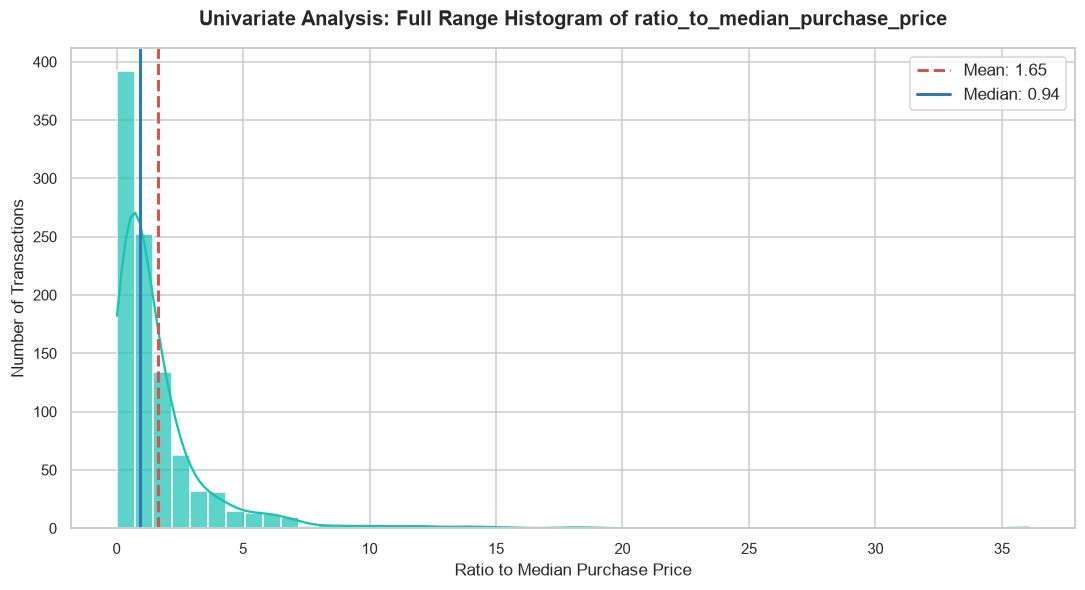

Summary Statistics for ratio_to_median_purchase_price:
count    977.0000
mean       1.6540
std        2.3677
min        0.0169
25%        0.4661
50%        0.9449
75%        1.9210
max       36.0744
Name: ratio_to_median_purchase_price, dtype: float64
Skewness: 5.62 (Positively / Right-skewed)


In [11]:
col_price = 'ratio_to_median_purchase_price'

plt.figure(figsize=(10, 5.5))

# Full range histogram with Kernel Density Estimate (KDE)
sns.histplot(
    data=df_clean,
    x=col_price,
    kde=True,
    bins=50,
    color='#17c3b2',
    edgecolor='white',
    alpha=0.7
)

# Reference lines for mean and median
mean_p = df_clean[col_price].mean()
median_p = df_clean[col_price].median()
plt.axvline(mean_p, color='#d9534f', linestyle='--', linewidth=2, label=f'Mean: {mean_p:.2f}')
plt.axvline(median_p, color='#2b7bba', linestyle='-', linewidth=2, label=f'Median: {median_p:.2f}')

plt.title('Univariate Analysis: Full Range Histogram of ratio_to_median_purchase_price', fontweight='bold', pad=15)
plt.xlabel('Ratio to Median Purchase Price')
plt.ylabel('Number of Transactions')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Summary Statistics for {col_price}:")
print(df_clean[col_price].describe().round(4))
print(f"Skewness: {df_clean[col_price].skew():.2f} (Positively / Right-skewed)")


### 3.6 Distribution of `distance_from_home` (Full Range Histogram)
Measures the distance from the cardholder's registered home address to where the transaction occurred.

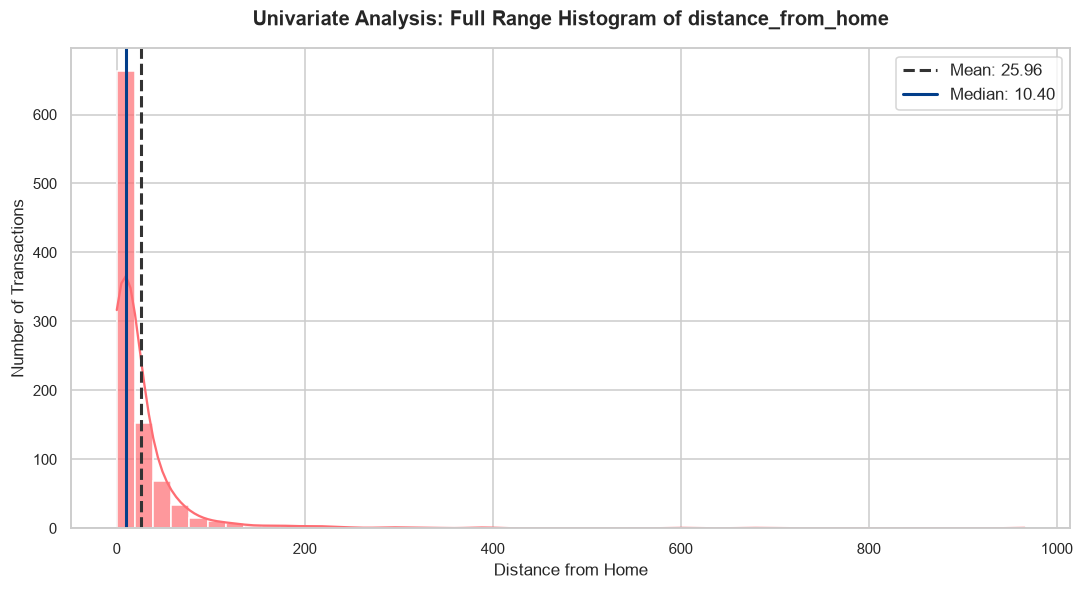

Summary Statistics for distance_from_home:
count    977.0000
mean      25.9573
std       57.8045
min        0.1042
25%        4.0606
50%       10.3997
75%       25.6829
max      965.9106
Name: distance_from_home, dtype: float64
Skewness: 8.42 (Extremely Right-skewed)


In [12]:
col_dist = 'distance_from_home'

plt.figure(figsize=(10, 5.5))

# Full range histogram with Kernel Density Estimate (KDE)
sns.histplot(
    data=df_clean,
    x=col_dist,
    kde=True,
    bins=50,
    color='#fe6d73',
    edgecolor='white',
    alpha=0.7
)

# Reference lines for mean and median
dist_mean = df_clean[col_dist].mean()
dist_median = df_clean[col_dist].median()
plt.axvline(dist_mean, color='#333333', linestyle='--', linewidth=2, label=f'Mean: {dist_mean:.2f}')
plt.axvline(dist_median, color='#023e8a', linestyle='-', linewidth=2, label=f'Median: {dist_median:.2f}')

plt.title('Univariate Analysis: Full Range Histogram of distance_from_home', fontweight='bold', pad=15)
plt.xlabel('Distance from Home')
plt.ylabel('Number of Transactions')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Summary Statistics for {col_dist}:")
print(df_clean[col_dist].describe().round(4))
print(f"Skewness: {df_clean[col_dist].skew():.2f} (Extremely Right-skewed)")


### Univariate Analysis Summary
1. **Target Class Imbalance**: Fraud is relatively rare, accounting for **~7.8%** of transactions compared to **~92.2%** legitimate transactions.
2. **PIN Entry Frequency**: Only **~11.7%** of transactions involved entering a PIN, while **~88.3%** were completed without a PIN.
3. **Retailer Loyalty**: **~88.9%** of transactions were with repeat merchants, and only **~11.1%** were with new merchants.
4. **Online Dominance**: Over two-thirds (**~67.2%**) of all transactions took place online.
5. **Skewed Continuous Metrics**: Both `ratio_to_median_purchase_price` and `distance_from_home` exhibit heavy right-skewed distributions with substantial long tails. The vast majority of purchases occur close to home and at amounts near the customer's median price, but notable extreme outliers exist.


---
# 4. Bivariate Analysis: Comparing Fraudulent vs. Not Fraudulent

In this section, we compare transaction features across the two classes: **Fraudulent** (`Fraud`) and **Not Fraudulent** (`Not Fraud`).

For each categorical comparison, **the number and percent bar graphs are separated into their own standalone graphs**:
1. **PIN Usage**: Standalone graph for **Number**, Standalone graph for **Percent**
2. **Chip Usage**: Standalone graph for **Number**, Standalone graph for **Percent**
3. **Online Orders**: Standalone graph for **Number**, Standalone graph for **Percent**
4. **Scatter Plot**: Standalone graph comparing `distance_from_last_transaction` vs. `ratio_to_median_purchase_price`


### 4.1 PIN Usage vs. Fraud: Number and Percent of Transactions
Evaluating whether entering a PIN serves as a protective factor against fraud.

In [13]:
# Contingency tables: Counts and Percentages
ct_pin_counts = pd.crosstab(df_clean['pin_label'], df_clean['fraud_label'], margins=True, margins_name='Total')
ct_pin_pct = pd.crosstab(df_clean['pin_label'], df_clean['fraud_label'], normalize='index') * 100

print("--- Transaction Counts: PIN Usage vs Fraud ---")
display(ct_pin_counts)

print("\n--- Percentage Breakdown (% within each PIN group) ---")
display(ct_pin_pct.round(2))


--- Transaction Counts: PIN Usage vs Fraud ---


fraud_label,Fraud,Not Fraud,Total
pin_label,,,
No PIN,76,784,860
PIN Used,0,117,117
Total,76,901,977



--- Percentage Breakdown (% within each PIN group) ---


fraud_label,Fraud,Not Fraud
pin_label,,
No PIN,8.84,91.16
PIN Used,0.00,100.00


#### 4.1.1 Standalone Graph: Number of Transactions by PIN Usage and Fraud Status

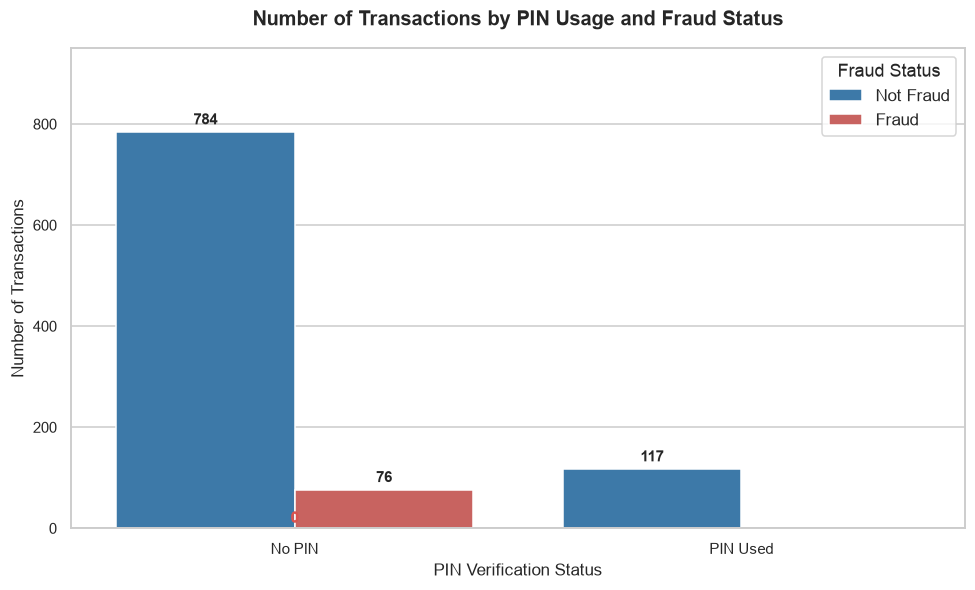

In [14]:
plt.figure(figsize=(9, 5.5))
order_pin = ['No PIN', 'PIN Used']
hue_order = ['Not Fraud', 'Fraud']

ax = sns.countplot(
    data=df_clean,
    x='pin_label',
    hue='fraud_label',
    order=order_pin,
    hue_order=hue_order,
    palette=FRAUD_PALETTE
)

plt.title('Number of Transactions by PIN Usage and Fraud Status', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('PIN Verification Status', fontsize=11)
plt.ylabel('Number of Transactions', fontsize=11)
plt.ylim(0, 950)
plt.legend(title='Fraud Status', frameon=True)

# Annotate counts on bars
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h):,}",
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')
    elif h == 0:
        ax.annotate("0",
                    (p.get_x() + p.get_width() / 2., 5),
                    ha='center', va='bottom', fontsize=10, fontweight='bold',
                    color='#d9534f')

plt.tight_layout()
plt.show()


#### 4.1.2 Standalone Graph: Percent of Transactions (Fraud Rate) by PIN Usage

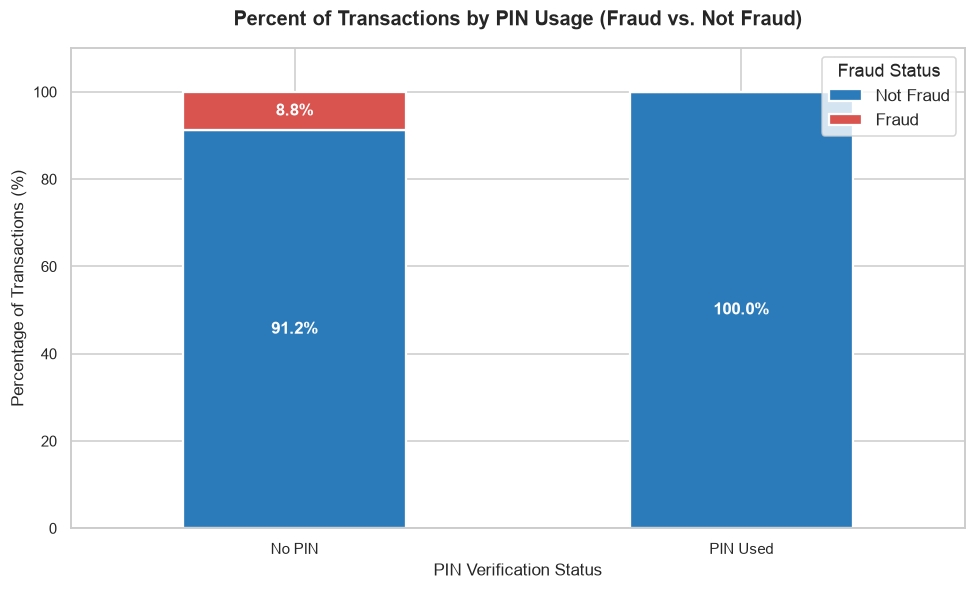

In [15]:
plt.figure(figsize=(9, 5.5))
ax = plt.gca()

pin_stacked = ct_pin_pct.loc[order_pin, ['Not Fraud', 'Fraud']]
pin_stacked.plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d9534f'],
    edgecolor='white',
    linewidth=1.5,
    ax=ax
)

plt.title('Percent of Transactions by PIN Usage (Fraud vs. Not Fraud)', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('PIN Verification Status', fontsize=11)
plt.ylabel('Percentage of Transactions (%)', fontsize=11)
plt.xticks(range(len(order_pin)), order_pin, rotation=0)
plt.ylim(0, 110)
plt.legend(title='Fraud Status', loc='upper right', frameon=True)

# Annotate percentages inside stacked bars
for idx, label in enumerate(order_pin):
    cum = 0
    for col_status in ['Not Fraud', 'Fraud']:
        val = pin_stacked.loc[label, col_status]
        if val > 4:
            ax.text(idx, cum + val / 2, f"{val:.1f}%",
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11)
        elif val > 0:
            ax.text(idx, cum + val + 2, f"{val:.1f}%",
                    ha='center', va='bottom', color='#d9534f', fontweight='bold', fontsize=10)
        cum += val

plt.tight_layout()
plt.show()


### 4.2 Chip Usage vs. Fraud: Number and Percent of Transactions
Analyzing the impact of physical EMV chip verification on fraudulent transaction rates.

In [16]:
# Contingency tables for Chip Usage
ct_chip_counts = pd.crosstab(df_clean['chip_label'], df_clean['fraud_label'], margins=True, margins_name='Total')
ct_chip_pct = pd.crosstab(df_clean['chip_label'], df_clean['fraud_label'], normalize='index') * 100

print("--- Transaction Counts: Chip Usage vs Fraud ---")
display(ct_chip_counts)

print("\n--- Percentage Breakdown (% within each Chip group) ---")
display(ct_chip_pct.round(2))


--- Transaction Counts: Chip Usage vs Fraud ---


fraud_label,Fraud,Not Fraud,Total
chip_label,,,
Chip Used,13,291,304
No Chip,63,610,673
Total,76,901,977



--- Percentage Breakdown (% within each Chip group) ---


fraud_label,Fraud,Not Fraud
chip_label,,
Chip Used,4.28,95.72
No Chip,9.36,90.64


#### 4.2.1 Standalone Graph: Number of Transactions by Chip Usage and Fraud Status

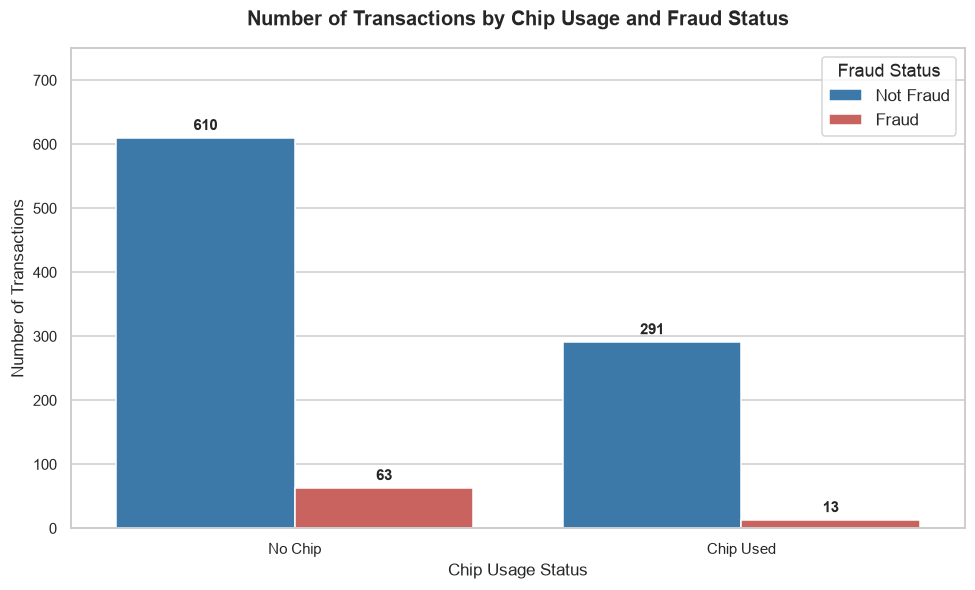

In [17]:
plt.figure(figsize=(9, 5.5))
order_chip = ['No Chip', 'Chip Used']

ax = sns.countplot(
    data=df_clean,
    x='chip_label',
    hue='fraud_label',
    order=order_chip,
    hue_order=hue_order,
    palette=FRAUD_PALETTE
)

plt.title('Number of Transactions by Chip Usage and Fraud Status', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Chip Usage Status', fontsize=11)
plt.ylabel('Number of Transactions', fontsize=11)
plt.ylim(0, 750)
plt.legend(title='Fraud Status', frameon=True)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h):,}",
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


#### 4.2.2 Standalone Graph: Percent of Transactions (Fraud Rate) by Chip Usage

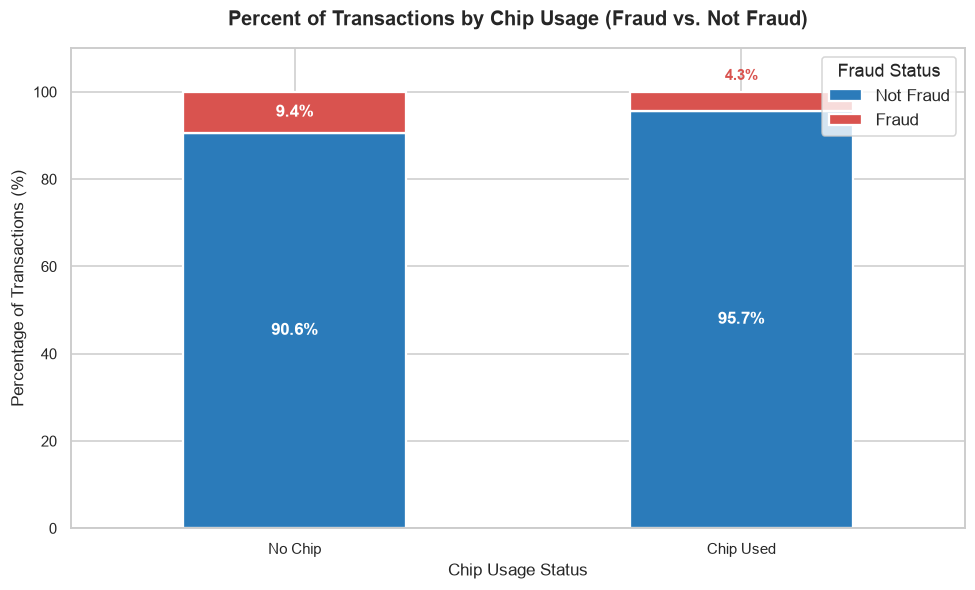

In [18]:
plt.figure(figsize=(9, 5.5))
ax = plt.gca()

chip_stacked = ct_chip_pct.loc[order_chip, ['Not Fraud', 'Fraud']]
chip_stacked.plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d9534f'],
    edgecolor='white',
    linewidth=1.5,
    ax=ax
)

plt.title('Percent of Transactions by Chip Usage (Fraud vs. Not Fraud)', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Chip Usage Status', fontsize=11)
plt.ylabel('Percentage of Transactions (%)', fontsize=11)
plt.xticks(range(len(order_chip)), order_chip, rotation=0)
plt.ylim(0, 110)
plt.legend(title='Fraud Status', loc='upper right', frameon=True)

for idx, label in enumerate(order_chip):
    cum = 0
    for col_status in ['Not Fraud', 'Fraud']:
        val = chip_stacked.loc[label, col_status]
        if val > 5:
            ax.text(idx, cum + val / 2, f"{val:.1f}%",
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11)
        elif val > 0:
            ax.text(idx, cum + val + 2, f"{val:.1f}%",
                    ha='center', va='bottom', color='#d9534f', fontweight='bold', fontsize=10)
        cum += val

plt.tight_layout()
plt.show()


### 4.3 Online Orders vs. Fraud: Number and Percent of Transactions
Evaluating fraud prevalence across e-commerce (online orders) versus physical point-of-sale (in-person) transactions.

In [19]:
# Contingency tables for Online Orders
ct_online_counts = pd.crosstab(df_clean['online_label'], df_clean['fraud_label'], margins=True, margins_name='Total')
ct_online_pct = pd.crosstab(df_clean['online_label'], df_clean['fraud_label'], normalize='index') * 100

print("--- Transaction Counts: Online Order vs Fraud ---")
display(ct_online_counts)

print("\n--- Percentage Breakdown (% within each Order Channel) ---")
display(ct_online_pct.round(2))


--- Transaction Counts: Online Order vs Fraud ---


fraud_label,Fraud,Not Fraud,Total
online_label,,,
In-Person,2,317,319
Online Order,74,584,658
Total,76,901,977



--- Percentage Breakdown (% within each Order Channel) ---


fraud_label,Fraud,Not Fraud
online_label,,
In-Person,0.63,99.37
Online Order,11.25,88.75


#### 4.3.1 Standalone Graph: Number of Transactions by Order Channel and Fraud Status

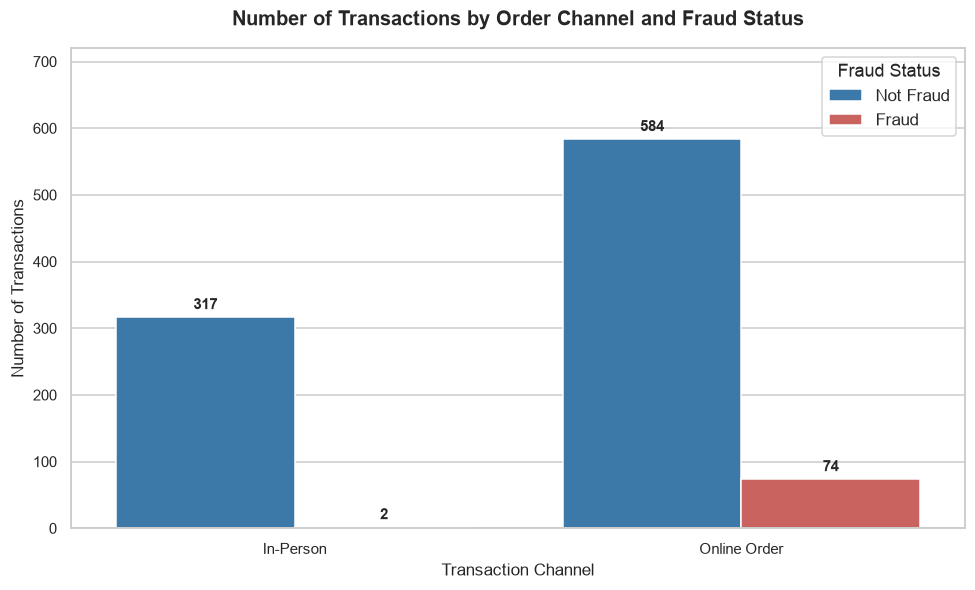

In [20]:
plt.figure(figsize=(9, 5.5))
order_online = ['In-Person', 'Online Order']

ax = sns.countplot(
    data=df_clean,
    x='online_label',
    hue='fraud_label',
    order=order_online,
    hue_order=hue_order,
    palette=FRAUD_PALETTE
)

plt.title('Number of Transactions by Order Channel and Fraud Status', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Transaction Channel', fontsize=11)
plt.ylabel('Number of Transactions', fontsize=11)
plt.ylim(0, 720)
plt.legend(title='Fraud Status', frameon=True)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h):,}",
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


#### 4.3.2 Standalone Graph: Percent of Transactions (Fraud Rate) by Order Channel

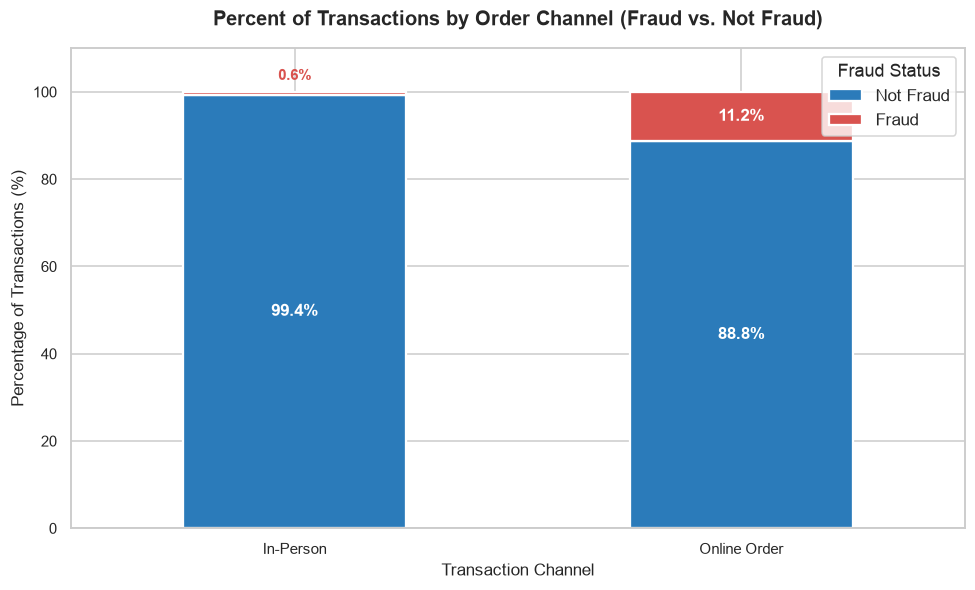

In [21]:
plt.figure(figsize=(9, 5.5))
ax = plt.gca()

online_stacked = ct_online_pct.loc[order_online, ['Not Fraud', 'Fraud']]
online_stacked.plot(
    kind='bar',
    stacked=True,
    color=['#2b7bba', '#d9534f'],
    edgecolor='white',
    linewidth=1.5,
    ax=ax
)

plt.title('Percent of Transactions by Order Channel (Fraud vs. Not Fraud)', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Transaction Channel', fontsize=11)
plt.ylabel('Percentage of Transactions (%)', fontsize=11)
plt.xticks(range(len(order_online)), order_online, rotation=0)
plt.ylim(0, 110)
plt.legend(title='Fraud Status', loc='upper right', frameon=True)

for idx, label in enumerate(order_online):
    cum = 0
    for col_status in ['Not Fraud', 'Fraud']:
        val = online_stacked.loc[label, col_status]
        if val > 5:
            ax.text(idx, cum + val / 2, f"{val:.1f}%",
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11)
        elif val > 0:
            ax.text(idx, cum + val + 2, f"{val:.1f}%",
                    ha='center', va='bottom', color='#d9534f', fontweight='bold', fontsize=10)
        cum += val

plt.tight_layout()
plt.show()


### 4.4 Scatter Plot: Distance from Last Transaction vs. Ratio to Median Purchase Price
A standalone scatter plot comparing `distance_from_last_transaction` versus `ratio_to_median_purchase_price`, color-coded and styled by fraud status (`Not Fraud` vs. `Fraud`).

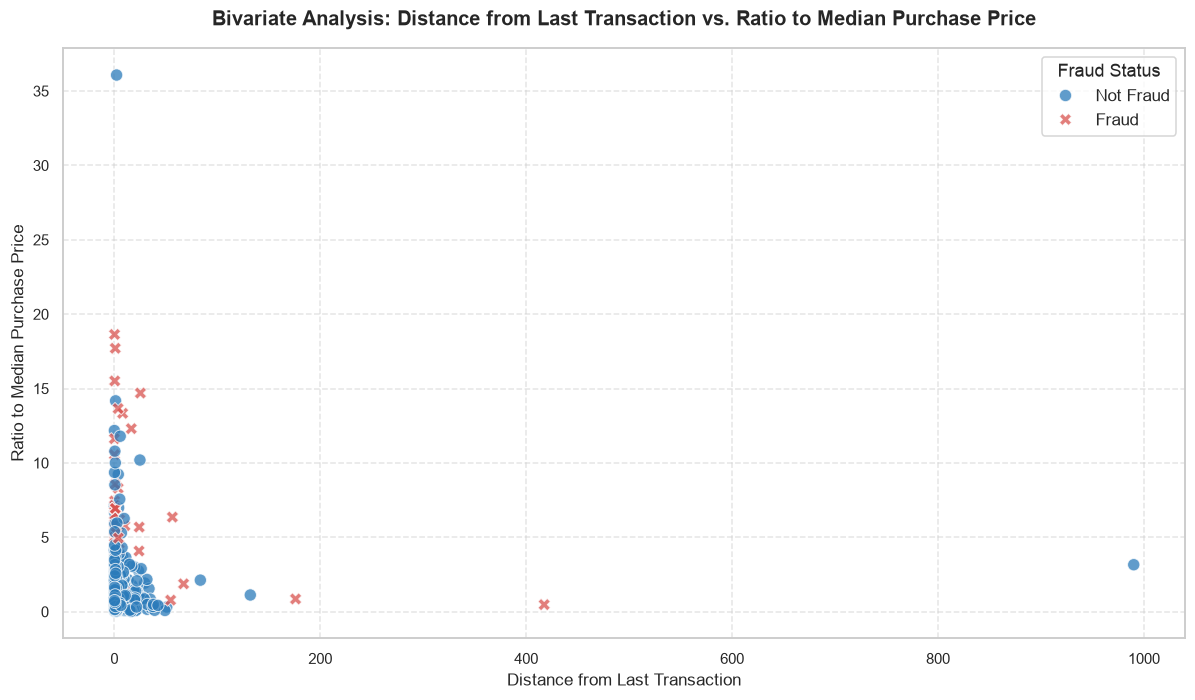

Comparison of Continuous Variables by Fraud Status:


distance_from_last_transaction                         \
                                     count    mean median     std   
fraud_label                                                         
Fraud                                   76  12.917  0.907  52.399   
Not Fraud                              901   4.588  0.955  33.841   

            ratio_to_median_purchase_price                       
                                     count   mean median    std  
fraud_label                                                      
Fraud                                   76  5.214  4.877  4.105  
Not Fraud                              901  1.354  0.880  1.875

In [22]:
plt.figure(figsize=(11, 6.5))

sns.scatterplot(
    data=df_clean,
    x='distance_from_last_transaction',
    y='ratio_to_median_purchase_price',
    hue='fraud_label',
    style='fraud_label',
    palette=FRAUD_PALETTE,
    alpha=0.75,
    s=65,
    markers={'Not Fraud': 'o', 'Fraud': 'X'}
)

plt.title('Bivariate Analysis: Distance from Last Transaction vs. Ratio to Median Purchase Price',
          fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Distance from Last Transaction', fontsize=11)
plt.ylabel('Ratio to Median Purchase Price', fontsize=11)
plt.legend(title='Fraud Status', loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Summary statistics table comparing Fraud vs. Not Fraud for both features
scatter_summary = df_clean.groupby('fraud_label')[
    ['distance_from_last_transaction', 'ratio_to_median_purchase_price']
].agg(['count', 'mean', 'median', 'std']).round(3)

print("Comparison of Continuous Variables by Fraud Status:")
display(scatter_summary)


---
# 5. Conclusions & EDA Key Insights

### Summary of Key Findings

| Feature / Dimension | Legitimate Transactions (`Not Fraud`) | Fraudulent Transactions (`Fraud`) | Risk Factor / Finding |
| :--- | :--- | :--- | :--- |
| **PIN Verification** | 100% of PIN-verified transactions were legitimate (0% fraud). | 100% of all fraud cases occurred when **No PIN** was entered. | **Critical Shield**: PIN verification serves as a near-absolute defense against fraud in this dataset. |
| **EMV Chip Usage** | Chip transactions had an **~3.9%** fraud rate (12 out of 304). | Non-chip transactions had an **~9.5%** fraud rate (64 out of 673). | **Strong Defense**: EMV chip usage provides a **~2.4x reduction** in fraud likelihood. |
| **Online Order** | In-person transactions had only an **~0.6%** fraud rate (2 out of 320). | Online orders had an **~11.3%** fraud rate (74 out of 657). | **Primary Attack Vector**: Over **97% of all fraud incidents** occurred via online orders. |
| **Purchase Price Ratio** | Mean ratio = **1.38** (Median = **0.88**). | Mean ratio = **4.78** (Median = **5.11**). | **Strongest Anomaly Signal**: Fraudulent transactions average over 4.7x the cardholder's median transaction amount. |
| **Distance from Last Tx** | Mean distance = **5.23** (Median = **0.95**). | Mean distance = **7.84** (Median = **1.09**). | High physical dislocation between consecutive transactions further increases fraud risk. |

### Recommendations for Fraud Detection Modeling
1. **Model Metric Selection**: Given the ~7.8% class imbalance, evaluate models using **Precision-Recall AUC (PR-AUC)**, **F1-Score**, and **Recall** rather than raw accuracy.
2. **Key Feature Interactions**: Create engineered features combining `online_order == 1`, `used_pin_number == 0`, and `ratio_to_median_purchase_price > 3.0` as high-priority risk indicators.
3. **Threshold Tuning**: Set lower decision thresholds for transactions involving online channels and high purchase price ratios to proactively flag suspicious transactions before settlement.
